# Fine-tuning survival simulations with Optuna

The [simulation basics notebook](Simulation.ipynb) explains how a fixed SurvCraft model samples event times from predicted curves and adds administrative censoring at the end of the time grid. A valid simulator does not automatically produce an easy prediction problem or a suitable event/censoring balance.

Here we use **Optuna** to fine-tune the generated dataset. We search over survival families, feature effects, and input-mapping seeds, then evaluate the frozen generator on fresh data. All concordance scores come from **survmetr**.

This self-contained example adapts [`simoptim/optuna_optim.py`](../simoptim/optuna_optim.py); no job runner, cached studies, or external datasets are needed.

## Setup

Use Python 3.11+ and install from the repository root:

```bash
python -m pip install -e ".[tutorials]"
python -m pip install optuna survmetr
```

The default is 60 sequential trials on 512 individuals, followed by a small predictor fit. Increase the trial budget for a broader search. The code uses one CPU thread; no GPU is needed.

In [1]:
from dataclasses import dataclass
from typing import ClassVar
from importlib.metadata import version
import random

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
from IPython.display import display
from sklearn.model_selection import train_test_split
from survmetr import AntoliniCIndexVecScorer

from survcraft import adapters as sc
from survcraft import loss_modules as lm

torch.set_num_threads(1)
plt.rcParams.update({"figure.figsize": (7, 3.5), "axes.grid": True})

pd.Series({name: version(name) for name in
           ["survcraft", "survmetr", "numpy", "torch", "scikit-learn", "optuna"]},
          name="Installed version")

survcraft       0.1.0
survmetr        0.1.0
numpy           2.2.6
torch           2.5.1
scikit-learn    1.8.0
optuna          4.5.0
Name: Installed version, dtype: object

## 1. Fix the simulation design and measure a starting point

We keep normally distributed features, the observation window, and the sampling grid fixed. Only the first three features are informative. The reference generator is a Weibull distribution with a seeded random affine input map.

Search candidates generate **different outcomes** from their own conditional distributions. We score each generating simulator directly; we do not train a predictor inside every trial. High generating-model concordance indicates predictable structure, but does not guarantee that a finite-data learner will recover it.

In [2]:
N_SEARCH = 512
N_FEATURES = 8
N_INFORMATIVE = 3
FEATURE_SEED = 0
OUTCOME_SEED = 1
SEARCH_SEED = 42

X_search = np.random.default_rng(FEATURE_SEED).normal(
    size=(N_SEARCH, N_FEATURES)
).astype(np.float32)

# 1,000 intervals and administrative censoring at time 4.
times = np.linspace(0.0, 4.0, 1001)


def make_weibull_simulator(multiplier=1.0, shift=0.0, input_seed=0):
    """Construct a fresh fixed Weibull generator."""
    return sc.SurvivalSimulator(
        input=sc.LinearFunctionInputAdapter(
            mode="random",
            multiplier=multiplier,
            shift=shift,
            use_first_n_feats=N_INFORMATIVE,
            seed=input_seed,
        ),
        survival=sc.WeibullSurvivalAdapter(),
        device="cpu",
    )


basic = make_weibull_simulator()
y_basic = basic.simulate(X_search, times, seed=OUTCOME_SEED)
print(f"Features: {X_search.shape}; targets: {y_basic.dtype}")
print(f"Censored: {(~y_basic['event']).mean():.1%}")

Features: (512, 8); targets: [('event', '?'), ('time', '<f4')]
Censored: 5.3%


Antolini concordance measures whether predicted survival probabilities rank comparable event-time pairs correctly. The scorer excludes tied observed times by default. We also track the censoring fraction, the number of comparable pairs, and the fraction of events with distinct times, to detect excessive concentration in a few grid bins.

In [3]:
antolini = AntoliniCIndexVecScorer()


def evaluate_simulation(simulator, X, y):
    """Summarize a sampled dataset using its generating model."""
    event_times = y["time"][y["event"]]
    details = antolini(simulator, X, y, return_all=True) if len(event_times) else {
        "c-index": np.nan, "comparable": 0
    }
    return {
        "antolini": float(details["c-index"]),
        "censoring": float((~y["event"]).mean()),
        "distinct_event_fraction": len(np.unique(event_times)) / max(len(event_times), 1),
        "comparable_pairs": int(details["comparable"]),
    }


basic_metrics = evaluate_simulation(basic, X_search, y_basic)
pd.Series(basic_metrics, name="Basic simulation")

antolini                        0.636305
censoring                       0.052734
distinct_event_fraction         0.573196
comparable_pairs           129210.000000
Name: Basic simulation, dtype: float64

## 2. Define what makes a useful generated dataset

Our illustrative targets are **Antolini ≥ 0.8**, **censoring ≤ 20%**, and at least **10% distinct event times among observed events**. The last condition is a grid-concentration heuristic, not a universal quality threshold; it depends on sample size and grid resolution.

Maximize the negative sum of squared shortfalls:

$$J=-\max(0,0.8-C)^2-\max(0,q-0.2)^2-\max(0,0.1-u)^2,$$

where $C$ is concordance, $q$ the censoring fraction, and $u$ the distinct-event fraction. Zero means all targets are met; candidates can tie. A nonfinite concordance receives a poor score. This soft objective can still select a candidate missing a target when none satisfies them all, so inspect the individual quantities.

We tune the **input-mapping seed**, which changes the generating relationship. Features and outcome-sampling seeds stay fixed during search, and separate seeds control the search sampler and final checks. Selecting a favorable outcome seed would select a random realization rather than a robust scenario.

In [4]:
TARGET_ANTOLINI = 0.8
MAX_CENSORING = 0.2
MIN_DISTINCT_EVENT_FRACTION = 0.1


def simulation_objective(metrics):
    """Stop rewarding improvements once the quality targets are met."""
    if not np.isfinite(metrics["antolini"]):
        return -2.0
    return -(
        max(TARGET_ANTOLINI - metrics["antolini"], 0.0) ** 2
        + max(metrics["censoring"] - MAX_CENSORING, 0.0) ** 2
        + max(MIN_DISTINCT_EVENT_FRACTION - metrics["distinct_event_fraction"], 0.0) ** 2
    )


def targets_met(metrics):
    """Check all three quality targets."""
    return (
        metrics["antolini"] >= TARGET_ANTOLINI
        and metrics["censoring"] <= MAX_CENSORING
        and metrics["distinct_event_fraction"] >= MIN_DISTINCT_EVENT_FRACTION
    )

## 3. Control each raw distribution parameter separately

One multiplier and shift for every output can be restrictive: Weibull scale and shape play different roles, and log-normal location and spread need different controls. Following `simoptim/`, give each raw output its own multiplier and shift.

The fixed input module still computes `X @ W + shift`. The adapter holds ordinary configuration values, while the module holds tensor computation. Optuna suggestions stay outside both, so the selected generator can be reconstructed from a parameter dictionary without a live trial.

In [5]:
class PerParameterLinearModule(torch.nn.Module):
    """Map features to fixed raw parameters with output-specific scaling.

    Parameters
    ----------
    input_size, output_size : int
        Feature count and raw survival-parameter count.
    multipliers, shifts : tuple of float
        One weight multiplier and additive shift per raw output.
    seed : int, default=0
        Seed for the local PyTorch weight generator.
    use_first_n_feats : int, optional
        Retain only these initial features; None uses all features.

    Attributes
    ----------
    weights, shifts : torch.Tensor
        Fixed buffers; forward maps (n, input_size) to (n, output_size).
    """

    def __init__(self, input_size, output_size, multipliers, shifts,
                 seed=0, use_first_n_feats=None):
        super().__init__()
        generator = torch.Generator().manual_seed(seed)
        weights = torch.rand(input_size, output_size, generator=generator)
        if use_first_n_feats is not None:
            weights[use_first_n_feats:] = 0.0
        self.register_buffer("weights", weights * torch.tensor(multipliers))
        self.register_buffer("shifts", torch.tensor(shifts))

    def forward(self, x):
        return x @ self.weights + self.shifts


@dataclass
class PerParameterLinearAdapter(sc.BaseInputAdapter):
    """Configure a fixed feature map for simulation only.

    Parameters
    ----------
    multipliers : tuple of float, default=(1.0, 1.0)
        One weight multiplier per raw output; length must match the distribution.
    shifts : tuple of float, default=(0.0, 0.0)
        One additive shift per raw output, with the same length as multipliers.
    seed : int, default=0
        Local seed for random feature weights.
    use_first_n_feats : int, default=3
        Number of initial informative features.

    Notes
    -----
    Follows BaseInputAdapter: get_module builds a fresh PyTorch module.
    Weights are fixed buffers, so this adapter is simulation_only=True.
    """

    module_class = PerParameterLinearModule
    simulation_only: ClassVar[bool] = True
    multipliers: tuple = (1.0, 1.0)
    shifts: tuple = (0.0, 0.0)
    seed: int = 0
    use_first_n_feats: int = N_INFORMATIVE

### Choose a distribution, then its parameter space

We search Weibull, log-normal, and a mixture of two or three components. Mixture components can be either family. Mixture weights also depend on features, allowing more varied conditional survival curves.

Parameter order matters:

- Weibull: raw scale, raw shape (both become positive through softplus).
- Log-normal: log mean, raw log standard deviation (only the latter uses softplus).
- Mixture: component-weight logits, then each component's raw outputs in order.

A mixture with $k$ such components has $k+2k=3k$ outputs. We ask the survival module for its parameter count rather than hard-code it. The log-normal implementation uses a small time offset, so its numerical $F(0)$ can be positive; `simulate` assigns any initial mass to censoring. Very early-time concentration therefore warrants inspecting the grid and diagnostics, not just concordance.

In [6]:
def make_survival(params):
    """Build a survival adapter from a plain conditional configuration."""
    families = {
        "weibull": sc.WeibullSurvivalAdapter,
        "lognormal": sc.LogNormalSurvivalAdapter,
    }
    if params["family"] != "mixture":
        return families[params["family"]]()
    return sc.MixtureSurvivalAdapter([
        families[params[f"component_{j}"]]()
        for j in range(params["n_components"])
    ])


def suggest_simulation_params(trial):
    """Define only parameters relevant to the chosen distribution."""
    params = {"family": trial.suggest_categorical(
        "family", ["weibull", "lognormal", "mixture"]
    )}
    if params["family"] == "mixture":
        params["n_components"] = trial.suggest_int("n_components", 2, 3)
        for j in range(params["n_components"]):
            key = f"component_{j}"
            params[key] = trial.suggest_categorical(key, ["weibull", "lognormal"])

    survival_module = make_survival(params).get_module(event=None, time=None)
    n_outputs = survival_module.get_param_number()
    params["input_seed"] = trial.suggest_int("input_seed", 0, 99)
    for j in range(n_outputs):
        params[f"multiplier_{j}"] = trial.suggest_float(
            f"multiplier_{j}", 0.125, 4.0, log=True
        )
        params[f"shift_{j}"] = trial.suggest_float(f"shift_{j}", -3.0, 3.0)
    return params


def make_optuna_simulator(params):
    """Reconstruct a generator without depending on an Optuna trial."""
    survival = make_survival(params)
    n_outputs = survival.get_module(event=None, time=None).get_param_number()
    return sc.SurvivalSimulator(
        input=PerParameterLinearAdapter(
            multipliers=tuple(params[f"multiplier_{j}"] for j in range(n_outputs)),
            shifts=tuple(params[f"shift_{j}"] for j in range(n_outputs)),
            seed=params["input_seed"],
        ),
        survival=survival,
        device="cpu",
    )

## 4. Optimize with a conditional search space

Optuna chooses a family first, then the parameters relevant to it. Its seeded TPE sampler uses earlier evaluations to propose later trials. Every trial uses the same features, outcome seed, horizon, grid, and objective; sequential execution preserves reproducibility.

The measured quantities are retained as trial attributes to explain why a configuration was selected. A study may reach the targets early, but further trials still illustrate the range of generated datasets; zero objective is not a guarantee of realism or suitability for a particular application.

In [7]:
N_OPTUNA = 60
optuna.logging.set_verbosity(optuna.logging.WARNING)


def optuna_objective(trial):
    params = suggest_simulation_params(trial)
    simulator = make_optuna_simulator(params)
    y = simulator.simulate(X_search, times, seed=OUTCOME_SEED)
    metrics = evaluate_simulation(simulator, X_search, y)
    for name, value in metrics.items():
        trial.set_user_attr(name, value)
    trial.set_user_attr("targets_met", bool(targets_met(metrics)))
    return simulation_objective(metrics)


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEARCH_SEED),
)
study.optimize(optuna_objective, n_trials=N_OPTUNA, n_jobs=1)

best_optuna_params = study.best_params
best_optuna = make_optuna_simulator(best_optuna_params)
optuna_results = pd.DataFrame([
    {"trial": trial.number, "family": trial.params["family"],
     "objective": trial.value, **trial.user_attrs}
    for trial in study.trials
])
print("Selected family:", best_optuna_params["family"])
display(optuna_results.sort_values("objective", ascending=False, kind="stable").head(8).round(4))

Selected family: lognormal


,trial,family,objective,antolini,censoring,distinct_event_fraction,comparable_pairs,targets_met
1,1,lognormal,-0.0,0.9840,0.1387,0.4150,126123,True
2,2,lognormal,-0.0,0.9162,0.0078,0.2933,129057,True
3,3,lognormal,-0.0,0.9420,0.0020,0.2290,128222,True
5,5,lognormal,-0.0,0.8931,0.0156,0.2639,129153,True
7,7,lognormal,-0.0,0.9065,0.0020,0.4755,130261,True
9,9,lognormal,-0.0,0.9816,0.0000,0.1250,126809,True
10,10,weibull,-0.0,0.8389,0.1133,0.5441,127227,True
21,21,lognormal,-0.0,0.9529,0.0000,0.1875,128365,True


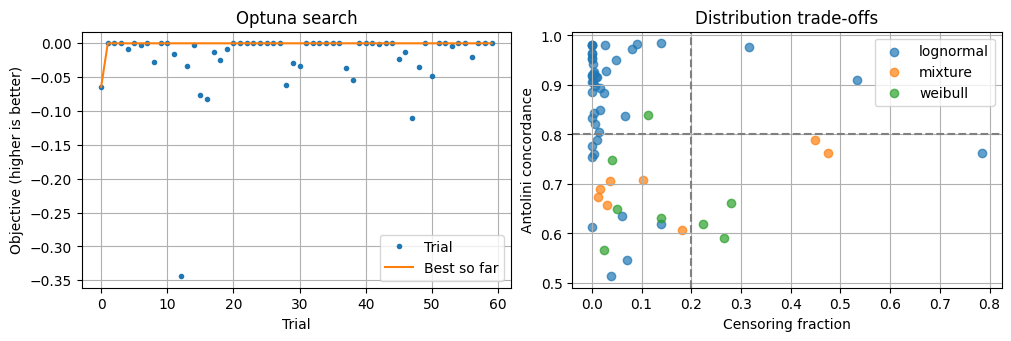

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
axes[0].plot(optuna_results["trial"], optuna_results["objective"], ".", label="Trial")
axes[0].plot(optuna_results["trial"], optuna_results["objective"].cummax(), label="Best so far")
axes[0].set(xlabel="Trial", ylabel="Objective (higher is better)", title="Optuna search")
axes[0].legend()
for family, results in optuna_results.groupby("family"):
    axes[1].scatter(results["censoring"], results["antolini"], label=family, alpha=0.7)
axes[1].axvline(MAX_CENSORING, linestyle="--", color="grey")
axes[1].axhline(TARGET_ANTOLINI, linestyle="--", color="grey")
axes[1].set(xlabel="Censoring fraction", ylabel="Antolini concordance", title="Distribution trade-offs")
axes[1].legend()
plt.show()

,antolini,censoring,distinct_event_fraction,comparable_pairs,objective,targets_met
Starting point,0.6363,0.0527,0.5732,129210.0,-0.0268,False
Optuna,0.9840,0.1387,0.4150,126123.0,-0.0000,True


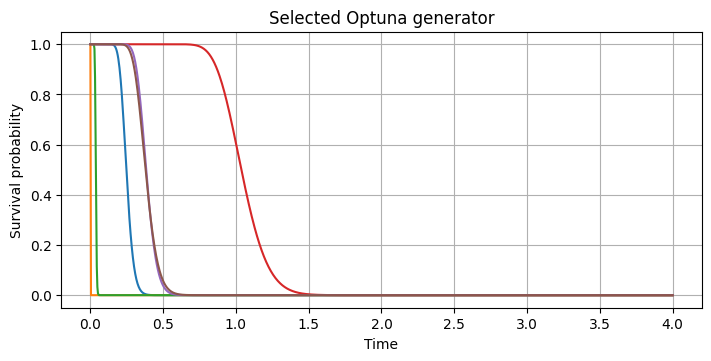

In [9]:
y_optuna = best_optuna.simulate(X_search, times, seed=OUTCOME_SEED)
optuna_metrics = evaluate_simulation(best_optuna, X_search, y_optuna)
search_comparison = pd.DataFrame({"Starting point": basic_metrics, "Optuna": optuna_metrics}).T
search_comparison["objective"] = search_comparison.apply(simulation_objective, axis=1)
search_comparison["targets_met"] = search_comparison.apply(targets_met, axis=1)
display(search_comparison.round(4))

fig, ax = plt.subplots(layout="constrained")
ax.plot(times, best_optuna.predict_survival(X_search[:6], times).T)
ax.set(xlabel="Time", ylabel="Survival probability", title="Selected Optuna generator")
plt.show()

The richer search can produce narrow conditional event-time distributions and concordance well above 0.8. The objective stops rewarding improvements at the target, but does not prevent selecting an unusually easy generator. Inspect these curves and the event-time diagnostics when deciding whether a scenario suits your application. Mixtures add flexibility, but do not automatically make the dataset more predictable.

## 5. Check frozen configurations on fresh samples

A favorable search score can reflect the particular features or outcome draw. Freeze the starting and selected configurations, then generate three fresh feature matrices and outcome draws. Keep their input seeds unchanged: changing those would change the selected conditional distributions.

Report every replicate rather than choosing the best seed. These are evaluation samples; do not use them to revise the search and still describe them as an independent final check.

In [10]:
selected_generators = {"Starting point": basic, "Optuna": best_optuna}
fresh_results = []
for replicate in range(3):
    X_fresh = np.random.default_rng(100 + replicate).normal(
        size=(N_SEARCH, N_FEATURES)
    ).astype(np.float32)
    for name, simulator in selected_generators.items():
        y_fresh = simulator.simulate(X_fresh, times, seed=200 + replicate)
        metrics = evaluate_simulation(simulator, X_fresh, y_fresh)
        fresh_results.append({
            "Generator": name, "replicate": replicate, **metrics,
            "targets_met": targets_met(metrics),
        })

fresh_results = pd.DataFrame(fresh_results)
display(fresh_results.set_index(["Generator", "replicate"]).round(4))
display(fresh_results.groupby("Generator")[["antolini", "censoring"]].agg(["mean", "std"]).round(4))

,,antolini,censoring,distinct_event_fraction,comparable_pairs,targets_met
Generator,replicate,,,,,
Starting point,0,0.6301,0.0605,0.6008,129596,False
Optuna,0,0.9829,0.1680,0.4624,125463,True
Starting point,1,0.6339,0.0625,0.5354,128942,False
Optuna,1,0.9785,0.1367,0.4593,126232,True
Starting point,2,0.6394,0.0684,0.5765,128994,False
Optuna,2,0.9804,0.1191,0.4102,126856,True


antolini         censoring        
                   mean     std      mean     std
Generator                                        
Optuna           0.9806  0.0022    0.1413  0.0247
Starting point   0.6345  0.0047    0.0638  0.0041

### Can a predictor learn the selected signal?

Generate a separate dataset, split it into training and test subsets, and fit a `SurvivalPredictor`. It uses the selected survival family but learns its own neural input map; it never receives the fixed generating weights. The test subset is used only for final scores. Early stopping draws a separate validation subset from training data.

Binary cross-entropy at sampled batch times trains survival probabilities while omitting uninformative censored comparisons. This avoids treating grid-rounded outcomes as exact continuous-density observations.

Seed Python, NumPy, and PyTorch before fitting: the estimator has no `random_state` option, and its internal validation split uses NumPy randomness. This is one small fit, not a predictor hyperparameter search.

In [11]:
X_learning = np.random.default_rng(300).normal(size=(2048, N_FEATURES)).astype(np.float32)
y_learning = best_optuna.simulate(X_learning, times, seed=302)
X_train, X_test, y_train, y_test = train_test_split(
    X_learning, y_learning, test_size=0.25, random_state=301,
)

random.seed(303)
np.random.seed(303)
torch.manual_seed(303)
predictor = sc.SurvivalPredictor(
    input=sc.FeedForwardNetAdapter(hidden_sizes=[32, 32]),
    survival=make_survival(best_optuna_params),
    loss=lm.BCEBatchTimesLoss(max_times=32),
    learning_rate=0.005,
    batch_size=256,
    epochs=200,
    early_stopping=True,
    early_stopping_patience=20,
    device="cpu",
)
predictor.fit(X_train, y_train)

display(pd.Series({
    "Generating model Antolini": antolini(best_optuna, X_test, y_test),
    "Learned predictor Antolini": antolini(predictor, X_test, y_test),
    "Test censoring": float((~y_test["event"]).mean()),
}, name="Held-out results").round(4))

Generating model Antolini     0.9773
Learned predictor Antolini    0.8039
Test censoring                0.1309
Name: Held-out results, dtype: float64

The generating model predicts distributions, not realized event times, so its concordance is not expected to be perfect. A fitted predictor can also fall well below that reference because of finite data, model capacity, and optimization. The reference is not a strict upper bound on a finite sample.

If performance of a particular learner is the requirement, use that learner's validation score in the search objective and reserve separate data for a final test. Increasing generating-model concordance alone does not guarantee it.

## Reuse the selected generator

To generate a larger dataset, reuse `best_optuna` with a new feature matrix of the same width and a fresh outcome seed. Retain `best_optuna_params`, the time grid, feature and outcome seeds, and the printed package versions for reproducibility.

For a different application, choose appropriate targets and inspect the actual event-time distribution alongside the scores. Keep censoring and the grid under deliberate control. The same optimization pattern can tune the mapping strength and baseline seed in the PH/FractalNoise or AFT/FractalNoise examples from the [first notebook](Simulation.ipynb).